# Hồi quy Logistic tối ưu bằng Gradient Descent

*Bài 4, mục 4.1.4.* Dự đoán xác suất thi đỗ theo số giờ ôn tập của 20 sinh viên. Hàm mất mát cross-entropy (thu được từ MLE):

$$\mathcal{L}(\mathbf{w}) = -\frac{1}{N}\sum_{i=1}^{N}\big[y_i \ln a_i + (1 - y_i)\ln(1 - a_i)\big], \qquad a_i = \sigma(\mathbf{x}_i^T\mathbf{w})$$

Gradient: $\nabla\mathcal{L}(\mathbf{w}) = \frac{1}{N}\mathbf{X}^T(\sigma(\mathbf{X}\mathbf{w}) - \mathbf{y})$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Dữ liệu: số giờ ôn tập và kết quả thi (1: đỗ, 0: trượt)
X = np.array([0.50, 0.75, 1.00, 1.25, 1.50, 1.75, 1.75, 2.00, 2.25, 2.50,
              2.75, 3.00, 3.25, 3.50, 4.00, 4.25, 4.50, 4.75, 5.00, 5.50])
y = np.array([0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1])

# Vector mở rộng: thêm cột 1 vào trước -> mỗi hàng là [1, x_i]
Xbar = np.column_stack([np.ones(len(X)), X])


def sigmoid(s):
    return 1 / (1 + np.exp(-s))


def loss(w, Xbar, y):
    a = sigmoid(Xbar @ w)
    return -np.mean(y * np.log(a) + (1 - y) * np.log(1 - a))

## 1. Tính tay một bước lặp

Khởi tạo $\mathbf{w} = [0, 0]$, $\eta = 0.5$. Khi đó mọi $a_i = 0.5$, $\mathcal{L} = \ln 2$.

In [2]:
w = np.zeros(2)
grad = Xbar.T @ (sigmoid(Xbar @ w) - y) / len(y)
print('L(0)     = %.4f (= ln 2)' % loss(w, Xbar, y))
print('gradient =', grad)
w1 = w - 0.5 * grad
print('w sau 1 bước =', w1, ' L = %.4f' % loss(w1, Xbar, y))

L(0)     = 0.6931 (= ln 2)
gradient = [ 0.      -0.50625]
w sau 1 bước = [0.       0.253125]  L = 0.6410


## 2. Chạy Gradient Descent đến khi hội tụ

In [3]:
def logistic_gd(Xbar, y, eta=0.5, n_iters=2000):
    w = np.zeros(Xbar.shape[1])
    history = [loss(w, Xbar, y)]
    for _ in range(n_iters):
        a = sigmoid(Xbar @ w)                    # xác suất dự đoán cho N mẫu
        grad = Xbar.T @ (a - y) / len(y)         # gradient = (1/N) X^T (a - y)
        w = w - eta * grad                       # cập nhật trọng số
        history.append(loss(w, Xbar, y))
    return w, history


w, history = logistic_gd(Xbar, y)
print('w0 = %.4f, w1 = %.4f' % (w[0], w[1]))
print('L(w) = %.4f' % history[-1])
print('Ranh giới quyết định: x = %.2f giờ' % (-w[0] / w[1]))
print('Mỗi giờ ôn thêm nhân odds thi đỗ lên %.2f lần' % np.exp(w[1]))

w0 = -4.0777, w1 = 1.5046
L(w) = 0.4015
Ranh giới quyết định: x = 2.71 giờ
Mỗi giờ ôn thêm nhân odds thi đỗ lên 4.50 lần


## 3. Xác suất thi đỗ theo số giờ ôn tập

1 giờ -> P(đỗ) = 0.071
2 giờ -> P(đỗ) = 0.256
3 giờ -> P(đỗ) = 0.607
4 giờ -> P(đỗ) = 0.874
5 giờ -> P(đỗ) = 0.969


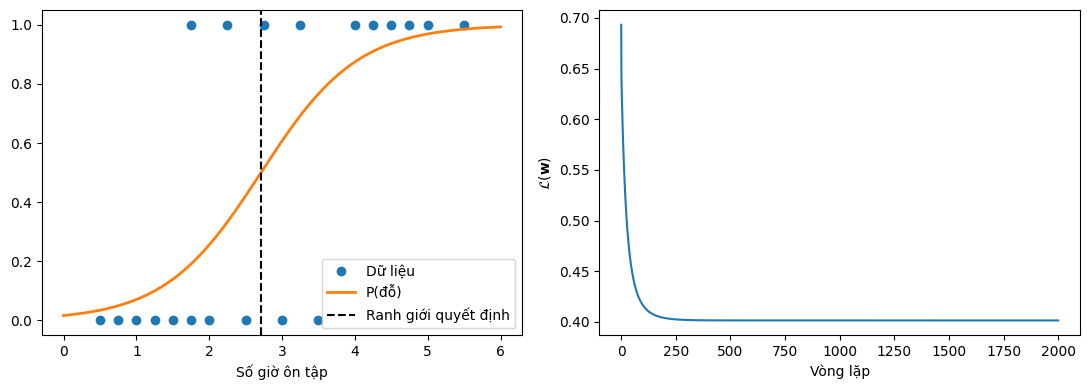

In [4]:
for hours in [1, 2, 3, 4, 5]:
    print(hours, 'giờ -> P(đỗ) = %.3f' % sigmoid(w[0] + w[1] * hours))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
x0 = np.linspace(0, 6, 300)
axes[0].plot(X, y, 'o', label='Dữ liệu')
axes[0].plot(x0, sigmoid(w[0] + w[1] * x0), lw=2, label='P(đỗ)')
axes[0].axvline(-w[0] / w[1], color='k', ls='--', label='Ranh giới quyết định')
axes[0].set_xlabel('Số giờ ôn tập'); axes[0].legend()
axes[1].plot(history)
axes[1].set_xlabel('Vòng lặp'); axes[1].set_ylabel(r'$\mathcal{L}(\mathbf{w})$')
plt.tight_layout()
plt.show()